# Fase 7.1 — Corrección del sesgo de selección temporal

V3 sustituye el protocolo v2; se conservan fuentes, informes, notebooks y resultados v2 en reports/historico/protocolo_v2. No se buscan mejores métricas: se cambia el objeto de evaluación a cohortes completas de llegada. Prueba queda cerrada, sin etiquetas ni scores para seleccionar estrategia.

## 1. Causa y alternativas, antes de entrenar

V2 usa alta aproximada = llegada menos lead_time y disponibilidad proxy = último estado más un día. Una cancelación anticipada puede estar disponible antes del corte aunque la llegada sea futura; una estancia no cancelada todavía no. La selección depende del resultado sin consultar explícitamente y.

A: cohortes por alta con seguimiento común serían preferibles para predicción al reservar, pero esta extracción por llegadas no acredita cohortes completas de altas ni snapshots. Darles seguimiento posterior común elimina el filtro individual, pero no simula conocer resultados antes del siguiente periodo de reservas. B: bloques por llegada, con seguimiento común y embargo, se ajustan al calendario cubierto por la fuente. Se elige B por diseño, no por sus métricas. Ver la propuesta previa protocolo_7_1_propuesta_previa.md.

Creación, llegada, fecha de resultado y cierre de seguimiento son conceptos distintos. Ni último estado ni llegada se convierten en predictor nuevo. Se mantienen los mismos 14 campos bajo su incertidumbre histórica.

## 2. V3: elegibilidad por fecha de llegada, sin y o estado

Train: 01/07/2015–30/06/2016, con seguimiento proxy completo antes de 01/09/2016. Julio-agosto se reservan como embargo. Validación: septiembre-diciembre 2016, con seguimiento completo antes de 01/03/2017. Enero-febrero 2017 son embargo. Prueba: marzo-agosto 2017, sin evaluar.

Si algún resultado o salida prevista incumple seguimiento de train/validación, falla el bloque entero: no se eliminan filas con resultados tardíos. La comprobación no demuestra ingestión real ni ausencia de actualizaciones faltantes. El cierre de prueba 01/12/2018 sigue siendo un supuesto retrospectivo sin acreditar y no se audita con resultados de prueba aquí.

Las fechas proxy de reserva pueden solaparse entre bloques: esta estrategia no simula decidir al alta. Mantiene orden de llegadas y disponibilidad proxy del bloque previo, bajo los supuestos declarados.

In [1]:
# EDICIÓN COMENTADA PARA LECTURA. Las fuentes ejecutadas y selladas permanecen en la raíz.
# Aplicar el protocolo v3 por llegada y cargar sus auditorías y resultados de desarrollo.
# Solo se añaden comentarios: no se han ejecutado instrucciones de esta copia.
from pathlib import Path
import sys
from IPython.display import display, Image
ROOT=Path.cwd()
if not (ROOT/"src").is_dir(): ROOT=ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from src.temporal_bias_v3 import run_v3
tables, verification=run_v3(ROOT)

Ajuste v3: regresion_logistica


Ajuste v3: xgboost


In [2]:
# EDICIÓN COMENTADA PARA LECTURA. Las fuentes ejecutadas y selladas permanecen en la raíz.
# Mostrar cómo la selección v2 dependía de la disponibilidad del desenlace.
# Solo se añaden comentarios: no se han ejecutado instrucciones de esta copia.
display(tables["auditoria_v2"].round(6))
display(tables["seleccion_resultado_v2"].round(6))

,grupo,modelo,n,canceladas,tasa_cancelacion,accuracy,precision,recall,f1,roc_auc,average_precision
0,validacion_v2_completa,regresion_logistica,18097,7753,0.428414,0.747085,0.807633,0.537727,0.645606,0.820718,0.807536
1,validacion_v2_completa,xgboost,18097,7753,0.428414,0.765707,0.862988,0.538630,0.663278,0.858927,0.842275
2,llegada_antes_2017,regresion_logistica,14180,3836,0.270522,0.735402,0.520290,0.280761,0.364714,0.709768,0.465509
3,llegada_antes_2017,xgboost,14180,3836,0.270522,0.753949,0.603706,0.263295,0.366673,0.772138,0.538114
4,llegada_desde_2017,regresion_logistica,3917,3917,1.000000,0.789380,1.000000,0.789380,0.882294,NaN,1.000000
5,llegada_desde_2017,xgboost,3917,3917,1.000000,0.808272,1.000000,0.808272,0.893971,NaN,1.000000


,resultado,incluidas_v2,apartadas_v2,proporcion_incluida
0,canceladas,7753,2252,0.774913
1,no_canceladas,10344,6223,0.624374


## 3. Particiones, seguimiento y trazabilidad

Se leen objetivos del preparado exclusivamente para IDs train/validación v3. El diagnóstico v2 utiliza scores/etiquetas de su validación ya archivada, sin abrir su prueba. Clases de prueba y embargos no se consultan; no disponible no significa cero. Las tablas de transición/exposición emplean solo IDs. La nueva prueba incluye casos expuestos en desarrollo v2, por lo que no es un holdout virgen.

In [3]:
# EDICIÓN COMENTADA PARA LECTURA. Las fuentes ejecutadas y selladas permanecen en la raíz.
# Revisar cohortes completas, embargos, seguimiento y exposición previa de prueba.
# Solo se añaden comentarios: no se han ejecutado instrucciones de esta copia.
display(tables["particiones"])
display(tables["seguimiento"])
display(tables["transicion_v2_v3"])
display(tables["exposicion_prueba"])

,particion,n,canceladas,no_canceladas,tasa_cancelacion,lead_p10,lead_mediana,lead_p90,llegada_min,llegada_max,reserva_proxy_min,reserva_proxy_max
0,entrenamiento,49157,17585.0,31572.0,0.357731,1.0,56.0,254.0,2015-07-01,2016-06-30,2013-06-24,2016-06-30
1,embargo_train_validacion,9635,NaN,NaN,NaN,6.0,117.0,245.0,2016-07-01,2016-08-31,2015-05-14,2016-08-31
2,validacion,19911,7570.0,12341.0,0.380192,4.0,66.0,313.0,2016-09-01,2016-12-31,2015-02-20,2016-12-31
3,embargo_validacion_prueba,7858,NaN,NaN,NaN,1.0,28.0,134.0,2017-01-01,2017-02-28,2015-07-10,2017-02-28
4,prueba_reservada,32829,NaN,NaN,NaN,6.0,103.0,264.0,2017-03-01,2017-08-31,2015-07-10,2017-08-31
5,fuera_cobertura,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,particion,registros,cierre_comun_exclusivo,max_disponibilidad_proxy,max_salida_prevista,etiquetas_posteriores_cierre,salidas_posteriores_cierre,min_margen_dias_disponibilidad,disponibilidad_real_garantizada
0,entrenamiento,49157,2016-09-01,2016-07-20,2016-07-19,0,0,43,False
1,validacion,19911,2017-03-01,2017-01-15,2017-01-14,0,0,45,False


particion,particion,embargo_train_validacion,embargo_validacion_prueba,entrenamiento,prueba_reservada,validacion
0,entrenamiento,2281,181,48671,319,2712
1,no_madura_entrenamiento,5079,184,486,1382,4958
2,no_madura_validacion,0,2086,0,6053,336
3,prueba_reservada,0,4208,0,22357,0
4,validacion,2275,1199,0,2718,11905


,destino_v3,origen_v2,n
0,prueba_reservada,entrenamiento,319
1,prueba_reservada,no_madura_entrenamiento,1382
2,prueba_reservada,validacion,2718
3,prueba_reservada,no_madura_validacion,6053
4,prueba_reservada,prueba_reservada,22357
5,embargo_validacion_prueba,entrenamiento,181
6,embargo_validacion_prueba,no_madura_entrenamiento,184
7,embargo_validacion_prueba,validacion,1199
8,embargo_validacion_prueba,no_madura_validacion,2086
9,embargo_validacion_prueba,prueba_reservada,4208


## 4. Logística inicial y XGBoost inicial

Dos pipelines nuevos con exactamente las fábricas anteriores. Imputación y codificación solo train; escalado solo logística; categorías desconocidas ignoradas. No se ajustan parámetros, calibración o umbral. Métricas a 0,5 exclusivamente en validación v3. Las métricas v2 quedan históricas y no se restan para afirmar una mejora o empeoramiento del algoritmo.

,modelo,accuracy,precision,recall,f1,roc_auc,average_precision,tn,fp,fn,tp,fit_seconds,predict_seconds
0,regresion_logistica,0.756567,0.772463,0.509908,0.614307,0.794590,0.762161,11204,1137,3710,3860,0.244782,0.021546
1,xgboost,0.758877,0.830508,0.459577,0.591717,0.830592,0.790062,11631,710,4091,3479,0.455004,0.037207


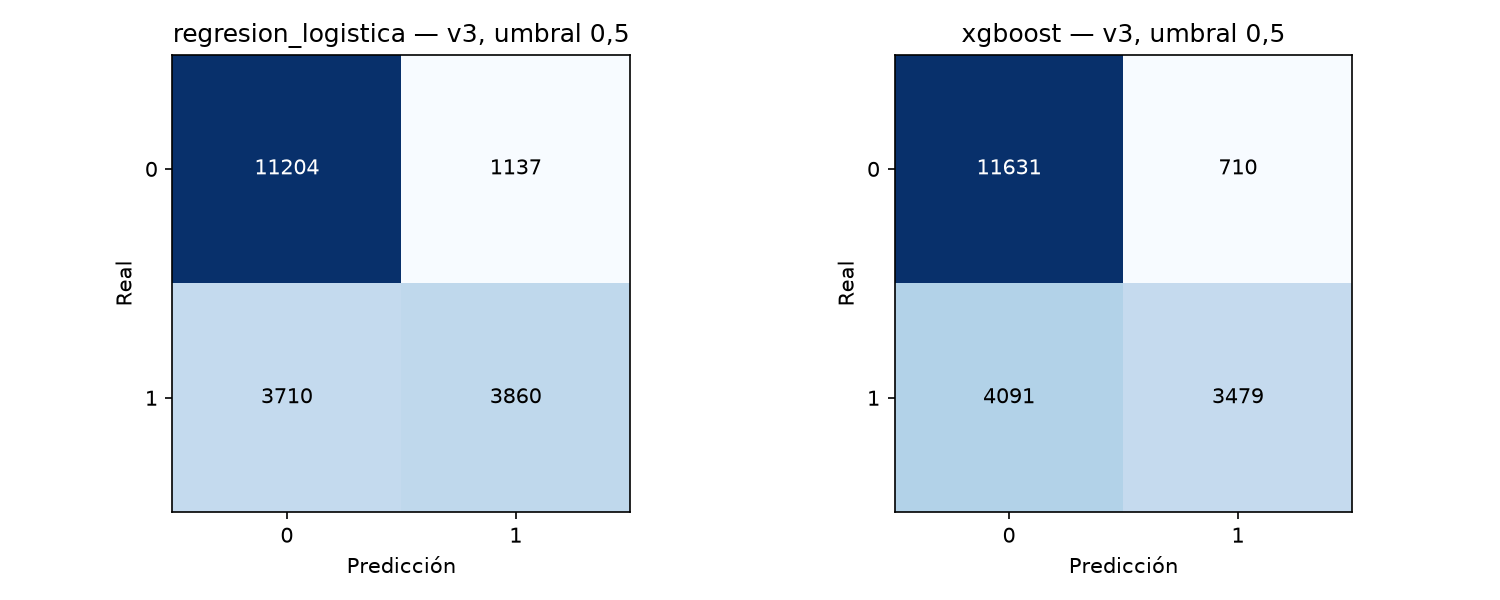

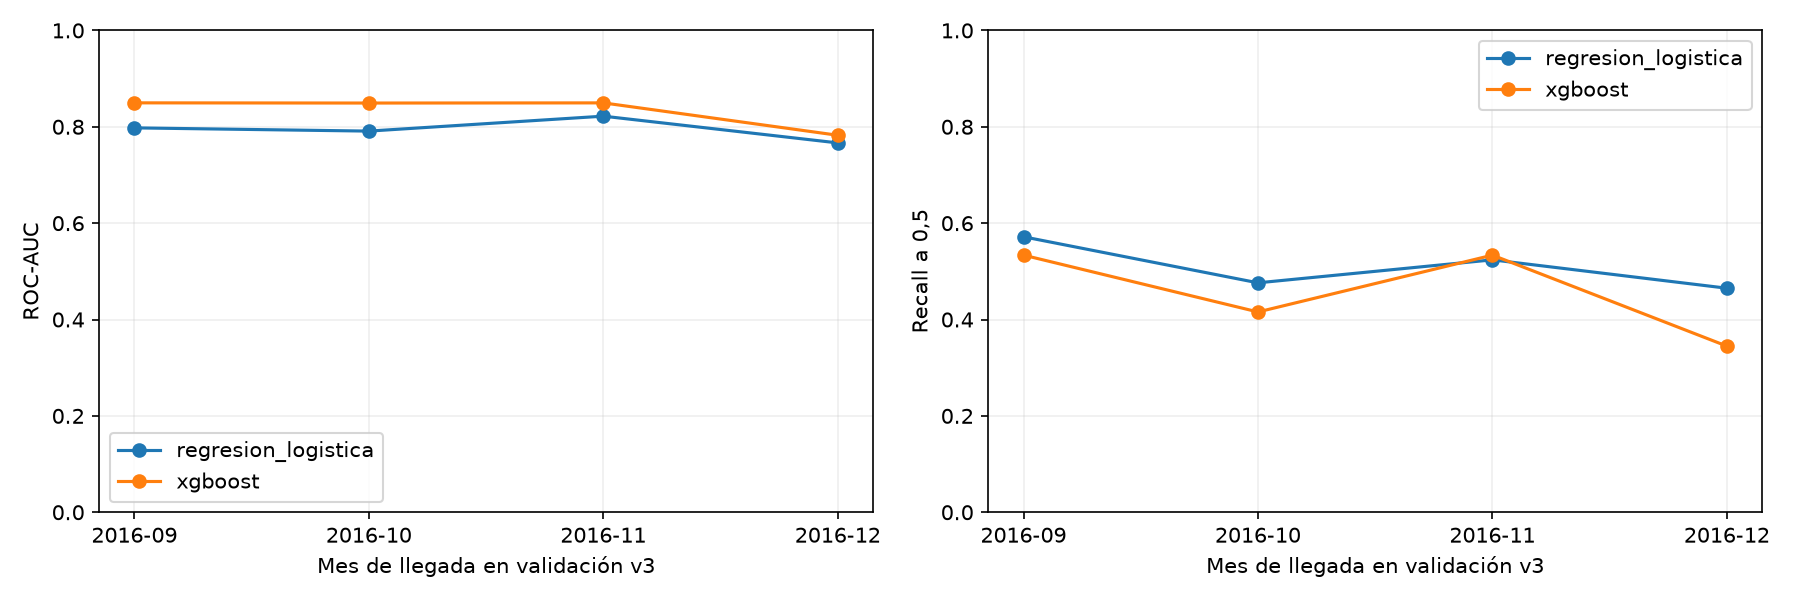

In [4]:
# EDICIÓN COMENTADA PARA LECTURA. Las fuentes ejecutadas y selladas permanecen en la raíz.
# Comparar logística y XGBoost iniciales en validación v3, sin usar prueba.
# Solo se añaden comentarios: no se han ejecutado instrucciones de esta copia.
display(tables["metricas"].round(6))
for name in ["matrices","estabilidad"]:
 display(Image(filename=str(ROOT/f"reports/figures/protocolo_7_1_{name}.png")))

## 5. Verificación del sesgo y limitaciones

V3 incluye todas las filas de cada cohorte elegida y no rescata cancelaciones con llegada futura. Se conserva la antelación completa dentro de cada bloque. Se comparan hoteles, meses y rangos de antelación con ambas clases y tamaño visible; segmentos pequeños o sin ambas clases se señalan. La prevalencia puede cambiar por estacionalidad y composición; no debe igualarse artificialmente.

No se ha corregido la selección original por llegadas, los duplicados, snapshots inciertos ni la exposición previa de validación/prueba ampliada. Esta es una evaluación retrospectiva exploratoria, no una garantía de predicción al crear la reserva. No se cambia la representación CSR heredada ni se introducen estados finales en X.

In [5]:
# EDICIÓN COMENTADA PARA LECTURA. Las fuentes ejecutadas y selladas permanecen en la raíz.
# Revisar segmentos y condiciones que acreditan el alcance de la corrección.
# Solo se añaden comentarios: no se han ejecutado instrucciones de esta copia.
display(tables["segmentos"].round(6))
# Hacer explícito este invariante: si falla, no se deben interpretar los resultados como válidos.
assert verification["filas_validacion_llegada_futura"]==0
# Hacer explícito este invariante: si falla, no se deben interpretar los resultados como válidos.
assert verification["ids_prueba_v1_v2_reutilizados_desarrollo"]==0
# Hacer explícito este invariante: si falla, no se deben interpretar los resultados como válidos.
assert verification["elegibilidad_invariante_a_etiqueta_y_estado"]
# Hacer explícito este invariante: si falla, no se deben interpretar los resultados como válidos.
assert verification["prueba_transformada_predicha_evaluada"] is False

,modelo,dimension,grupo,n,canceladas,no_canceladas,tasa_cancelacion,suficiente_descriptivo,probabilidad_media,accuracy,precision,recall,f1,roc_auc,average_precision
0,regresion_logistica,hotel,City Hotel,13690,5946,7744,0.434332,True,0.383323,0.731556,0.771067,0.543222,0.637395,0.805836,0.799854
1,regresion_logistica,hotel,Resort Hotel,6221,1624,4597,0.261051,True,0.215831,0.811606,0.779703,0.387931,0.518092,0.723919,0.602743
2,regresion_logistica,mes_llegada,2016-09,5394,2022,3372,0.374861,True,0.373821,0.757508,0.723404,0.571711,0.638674,0.797730,0.773074
3,regresion_logistica,mes_llegada,2016-10,6203,2514,3689,0.405288,True,0.313588,0.756892,0.862392,0.476134,0.613532,0.791028,0.777722
4,regresion_logistica,mes_llegada,2016-11,4454,1636,2818,0.367310,True,0.308466,0.775932,0.796468,0.523839,0.632006,0.822028,0.785417
5,regresion_logistica,mes_llegada,2016-12,3860,1398,2462,0.362176,True,0.325102,0.732383,0.695187,0.464950,0.557222,0.766532,0.697721
6,regresion_logistica,antelacion_grupo,0-7,2886,282,2604,0.097713,True,0.171281,0.856202,0.175610,0.127660,0.147844,0.641644,0.159353
7,regresion_logistica,antelacion_grupo,181+,5742,3291,2451,0.573145,True,0.615603,0.825845,0.844926,0.852628,0.848760,0.904439,0.938027
8,regresion_logistica,antelacion_grupo,31-90,5093,1801,3292,0.353623,True,0.210367,0.684076,0.679104,0.202110,0.311510,0.728048,0.587844
9,regresion_logistica,antelacion_grupo,8-30,3331,872,2459,0.261783,True,0.178840,0.752327,0.579125,0.197248,0.294269,0.700280,0.479543


## 6. Pruebas y cierre

Se comprueban fronteras, invariancia de asignación al cambiar etiqueta/estado, bloqueo de cohorte completa ante seguimiento tardío, rechazo de duplicados y lectura selectiva de etiquetas. El manifiesto cubre las 119.390 filas una vez. Los históricos están congelados con hashes y sus reejecuciones sobre v3 se bloquean para evitar sobrescritura accidental. No se realiza evaluación final ni se avanza de fase.

## Resultados y alcance de la corrección

Train: 49.157, cancelación 35,77%; validación: 19.911, cancelación 38,02%. Seguimiento observado completo según proxies, con márgenes mínimos 43 y 45 días hasta sus cierres. Las 17.493 filas de embargo y las 32.829 de prueba quedan fuera del desarrollo actual; sus clases no se consultan.

No hay llegadas futuras rescatadas en validación. En >180 días existen ahora ambas clases (3291 canceladas / 2451 no canceladas). XGBoost obtiene AUC 0,8306 y AP 0,7901, frente a 0,7946 y 0,7622 de logística, pero su recall (45,96%) y F1 (0,5917) son menores que logística (50,99% y 0,6143). Matrices: logística [[11204,1137],[3710,3860]]; XGBoost [[11631,710],[4091,3479]]. No se selecciona otro modelo o umbral por estos resultados.

Los 26.565 IDs de prueba anteriores se preservan en prueba o embargo. La nueva prueba incluye 319 antiguos train y 2718 antiguas validaciones v2, por lo que no recupera independencia. V3 corrige el mecanismo concreto de selección informativa; no acredita desempeño al alta, snapshots, cierre PMS ni generalización prospectiva. No se comparan diferencias numéricas con v2 como mejora del algoritmo. Se requiere revisar estas conclusiones antes de cualquier evaluación final.

In [6]:
# EDICIÓN COMENTADA PARA LECTURA. Las fuentes ejecutadas y selladas permanecen en la raíz.
# Verificar invariantes de v3 y que los históricos siguen intactos.
# Solo se añaden comentarios: no se han ejecutado instrucciones de esta copia.
import io,unittest
from src.comparison import sha
from src.temporal_bias_v3 import verify_history
log=io.StringIO()
# Ejecutar la batería indicada y conservar su salida; comprobar qué pruebas admite esta fase.
result=unittest.TextTestRunner(stream=log).run(unittest.defaultTestLoader.discover(str(ROOT/"tests")))
print(log.getvalue())
# Hacer explícito este invariante: si falla, no se deben interpretar los resultados como válidos.
assert result.wasSuccessful()
verify_history(ROOT)
for path,expected in verification["archivos_previos_intactos"].items(): assert sha(ROOT/path)==expected,path
print("Pruebas superadas:",result.testsRun)
print("Fin exclusivo de fase 7.1; informe reports/fase_7_1_correccion_sesgo_temporal.md")

C:\Users\panio\Documents\Curso\DataScience\proyecto_machineLearning\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


.....................................
----------------------------------------------------------------------
Ran 37 tests in 0.569s

OK

Pruebas superadas: 37
Fin exclusivo de fase 7.1; informe reports/fase_7_1_correccion_sesgo_temporal.md
